## Lab6-Assignment (Hawra Almadeh)

### 1. Importing Libraries and Loading the Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
EC_df = pd.read_csv('Ecommerce Customers')
EC_df.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


#### 1.1 Explore the Datset

In [4]:
EC_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 31.4 KB


As we can see from the data info we have three string columns and 5 numerical columns. All of which have the correct datat type.

In [5]:
EC_df.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [6]:
EC_df.columns

Index(['Email', 'Address', 'Avatar', 'Avg. Session Length', 'Time on App',
       'Time on Website', 'Length of Membership', 'Yearly Amount Spent'],
      dtype='str')

The dataset contains 8 attributes. Email whichs is customers emails. Address for customers addresses. Avatar is the useres perfered profile theme. Furthuremore, it has the avergae of the sessions, the time of which the useres spend in the app and the time spent on the website. Lastly, it has the length of each user membership aasuming it's in years since the last column is for the yearly spent amount by each customer.

In [ ]:
EC_df.isna().sum()

Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64

In [34]:
invalid_count = (~EC_df['Email'].str.contains('@', na=False)).sum()
print(invalid_count)


0


As exibitedd by the N/A values count, the data contains no missing or null values. In addition, we checked for invalied email values, and the results show zero invalid values. Since the data type for all numerical attributes has already been checked this also confirms that there are no invalid non-number values in these columns. The dataset doesn't need any preproccessing.

### 2. EDA

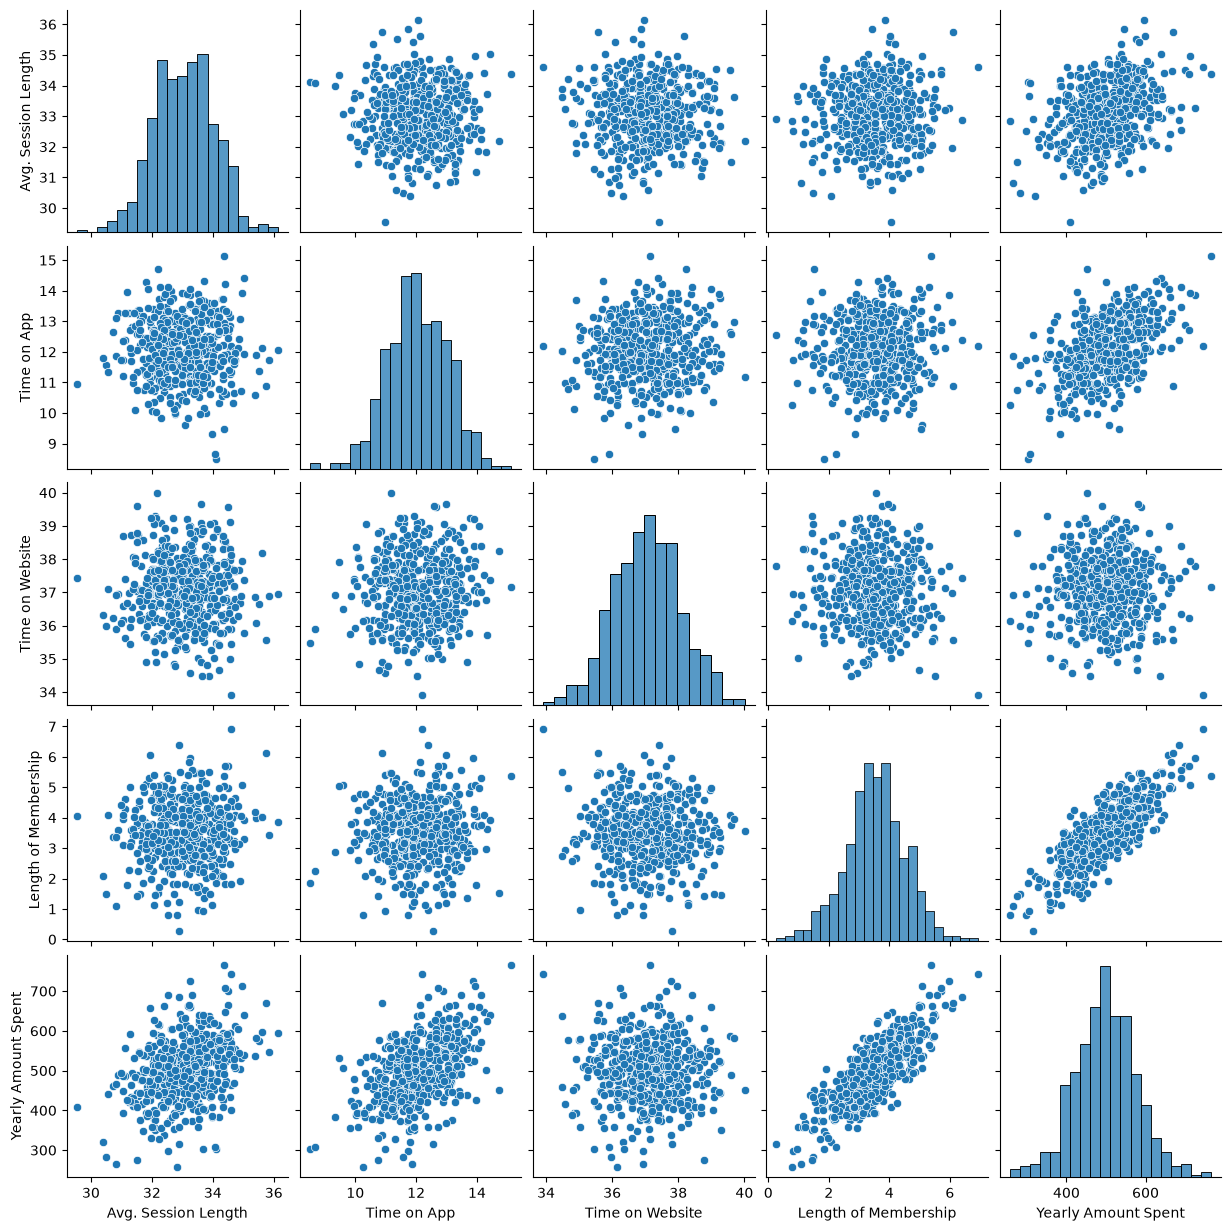

In [7]:
sns.pairplot(EC_df)

From the pair plot above we can see the spread of the data in relation to each pair of features. The plot shows a potential linear relationship between the Yearly Amount Spent and the customer Membership length. The rest of the data appears to be centered and randomly scattered forming a cirular cloud, which indicates the lack of relationship between these attributes.

C:\Users\hason\AppData\Local\Temp\ipykernel_32568\2879746801.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(EC_df["Yearly Amount Spent"])


<Axes: xlabel='Yearly Amount Spent', ylabel='Density'>

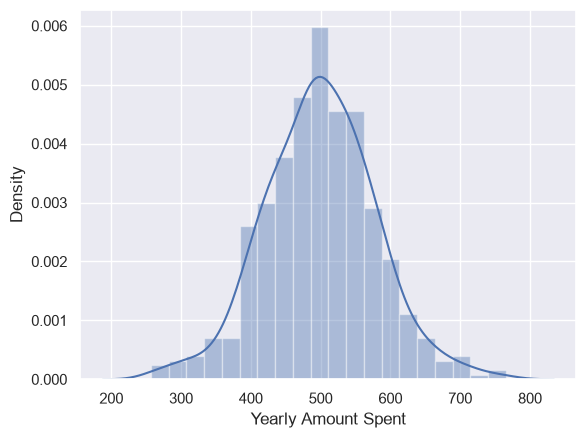

In [15]:
sns.distplot(EC_df["Yearly Amount Spent"])

<Axes: >

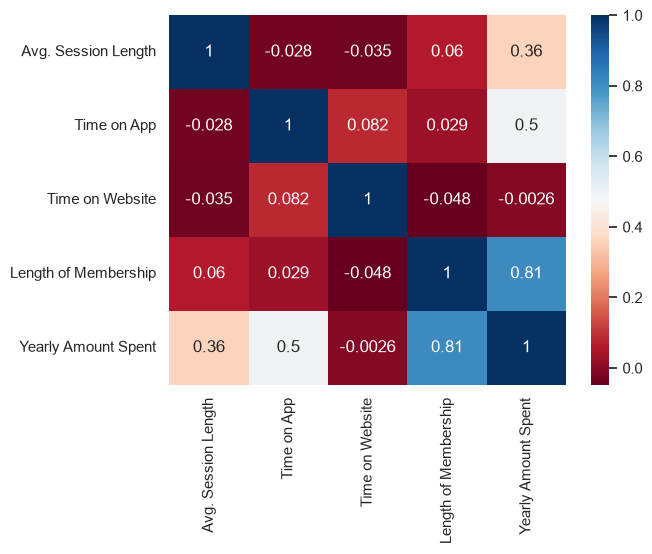

In [23]:
sns.heatmap(EC_df.corr(numeric_only=True), annot=True, cmap="RdBu")

As observed from the heatmap and correlation values above the Yearly Spent Amount and Length of Membership have moderatly strong linear relationship. In contrast, other attributes show nearly non-exsitance relationship just as we interperted from the pair plots.

### 3. Data Preperation & Train and Test Split

To get the data ready for the model. We start be assigning the columns for the input and output. And choosing the traget variable.

In [35]:
X = EC_df[['Avg. Session Length', 'Time on App','Time on Website', 'Length of Membership']]
y = EC_df['Yearly Amount Spent']

The X values represent the features the model is going to use in order to estimate a value for Y which is the Yearly Spent Amount by the customer. Now that we have the features ready we move on the Train /Test set split.

In [36]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=101)

### 4. Linear Regression Model

> **Important Note:** The assignment instructions specify using the same I am keeping the exect same configurations for the model as the lab file.

In [37]:
from sklearn.linear_model import LinearRegression
lm = LinearRegression()
lm.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[25.69,37.89, 0.56,61.65]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Avg. Session Length','Time on App','Time on Website', 'Length of Membership']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1045
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


#### 4.1 Model Evaluation

In [38]:
coeff_df = pd.DataFrame(lm.coef_,X.columns,columns=['Coefficient'])
coeff_df

,Coefficient
Avg. Session Length,25.691540
Time on App,37.892600
Time on Website,0.560581
Length of Membership,61.648594


Let's interpret these results. The coefficient analysis shows that for every one-unit increase in the average session length, the customer spends \$25.69 more, holding all other features constant. Similarly, the more time they spend on the app, their spending increases by \$37.89 per unit of time. Likewise, each time the customer's time on the website increases, their spending amount increases as well by \$0.56. Finally, the largest contributor to the customer spending amount is their membership length. The analysis suggests that for every one-unit increase in the customer's membership length, the customer spends \$61.65 more on the ecommerce app, assuming all other factors remain unchanged.

#### 4.2 Prediction using the model

In [39]:
predictions = lm.predict(X_test)

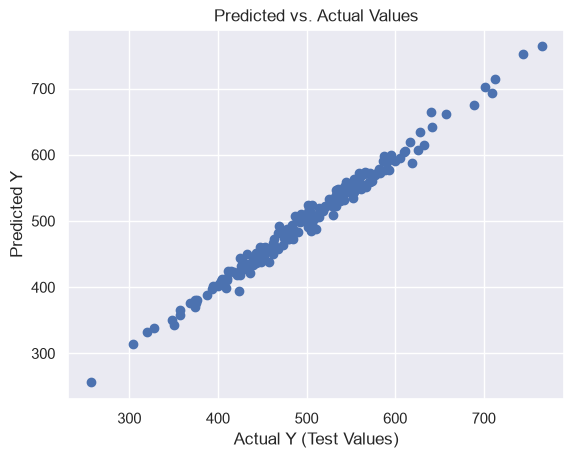

In [41]:
plt.scatter(y_test,predictions)
plt.xlabel('Actual Y (Test Values)')
plt.ylabel('Predicted Y')
plt.title('Predicted vs. Actual Values')
plt.show()

#### 4.3 Evaluation Metrcies

C:\Users\hason\AppData\Local\Temp\ipykernel_32568\1326397652.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_test-predictions),bins=50);


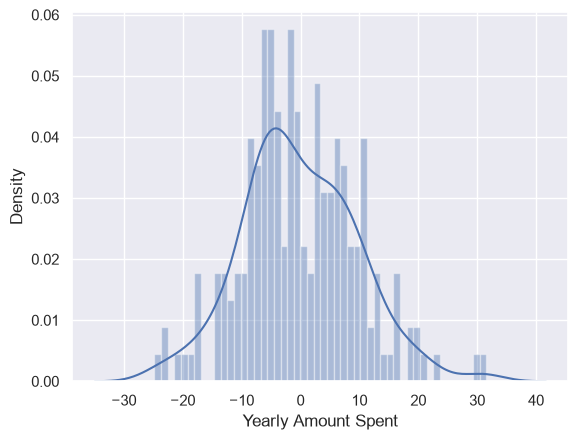

In [47]:
sns.distplot((y_test-predictions),bins=50);

The residual plot above illustrates the difference between the actual output and the model predictions. As we can see, the errors are mostly centered around zero, which suggests the model correctly predicts the majority of the data. Moreover, we can observe how larger errors are less likely to happen as the number of large errors decreases the further we move from the center, and the residuals form a symmetric, normal, bell-shaped distribution.

In [43]:
from sklearn import metrics
print('MAE:', metrics.mean_absolute_error(y_test, predictions))
print('MSE:', metrics.mean_squared_error(y_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions)))

MAE: 7.742671285838756
MSE: 93.83297800820064
RMSE: 9.686742383701583
